In [1]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [2]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

Linear / Uniform M 15.0 Z 10.5 obs 0.6966 expected 0.7 num 13931
Linear / Truncated normal M 33.4466 Z 10.5 obs 0.3118 expected 0.3139 num 6235
Gaussian (restricted) / Uniform M 3.0 Z 1.4677 obs 0.486 expected 0.4892 num 9719
Gaussian (restricted) / Truncated normal M 2.3299 Z 1.4677 obs 0.6254 expected 0.63 num 12508
Full normal / Normal sigma=1.0 M 1.7881 Z 1.0 obs 0.5638 expected 0.5593 num 11275
Full normal / Normal sigma=1.6 M 2.7218 Z 1.0 obs 0.3725 expected 0.3674 num 7450


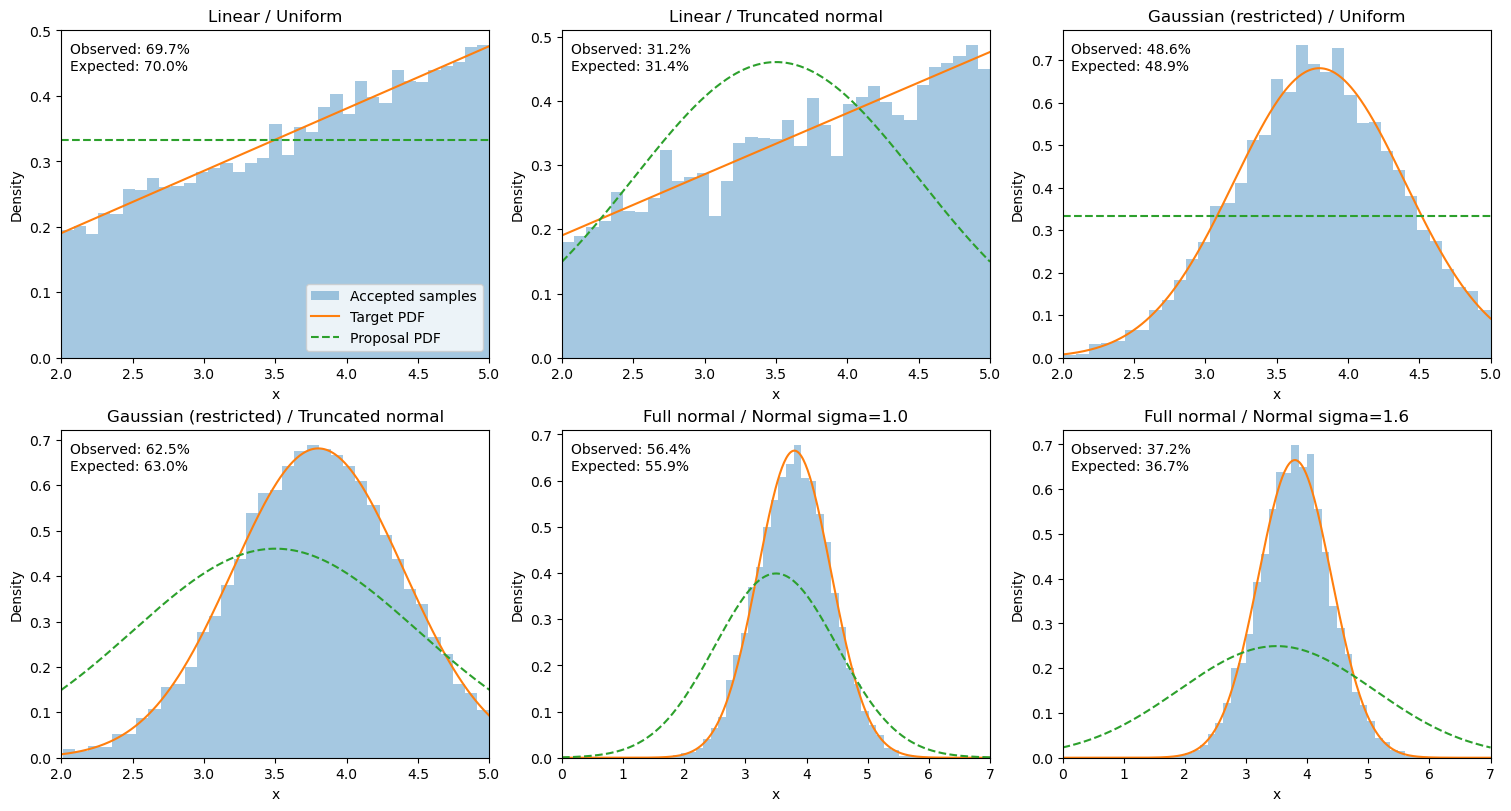

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.integrate import quad
from scipy.stats import uniform, truncnorm, norm

rng = np.random.default_rng(42)
bounds = (2.0, 5.0)
a, b = bounds

def f_linear(x):
    x = np.asarray(x)
    return np.where((a <= x) & (x <= b), x, 0.0)

def f_gaussian_bounded(x):
    x = np.asarray(x)
    return np.where((a <= x) & (x <= b), np.exp(-0.5*((x-3.8)/0.6)**2), 0.0)

q_uniform = uniform(loc=a, scale=b-a)
q_truncnorm = truncnorm((a-3.5)/1.0, (b-3.5)/1.0, loc=3.5, scale=1.0)

def envelope_on_interval(f, proposal, bounds):
    a,b = bounds
    grid = np.linspace(a,b,2001)
    ratio_grid = f(grid) / proposal.pdf(grid)
    result = minimize_scalar(lambda x: -float(f(x)/proposal.pdf(x)), bounds=bounds, method='bounded')
    M = max(float(np.max(ratio_grid)), -float(result.fun), float(f(a)/proposal.pdf(a)), float(f(b)/proposal.pdf(b)))
    return M * (1+1e-10)

def envelope_for_normals(target, proposal):
    mu_t, sig_t = target.mean(), target.std()
    mu_q, sig_q = proposal.mean(), proposal.std()
    if sig_q <= sig_t:
        raise ValueError('Proposal must be broader to guarantee bounded density ratio')
    x_star = (mu_t/sig_t**2 - mu_q/sig_q**2)/(1/sig_t**2 - 1/sig_q**2)
    return target.pdf(x_star)/proposal.pdf(x_star)

def rejection_sample(f,proposal,M,n=20000):
    x = proposal.rvs(size=n, random_state=rng)
    acc = f(x)/(M*proposal.pdf(x))
    if not np.all((acc >= 0) & (acc <= 1+1e-12)):
        raise ValueError('Invalid M or support')
    keep = rng.random(n) <= acc
    return x[keep], np.mean(keep)

cases=[]
for name,f in [('Linear',f_linear),('Gaussian (restricted)',f_gaussian_bounded)]:
    Z=quad(lambda x: float(f(x)),a,b)[0]
    for q_name,q in [('Uniform',q_uniform),('Truncated normal',q_truncnorm)]:
        M=envelope_on_interval(f,q,bounds)
        cases.append((f'{name} / {q_name}',f,q,M,Z,bounds))

target_full = norm(loc=3.8,scale=0.6)
for q_name, q in [('Normal sigma=1.0',norm(loc=3.5,scale=1.0)),('Normal sigma=1.6',norm(loc=3.5,scale=1.6))]:
    M=envelope_for_normals(target_full,q)
    cases.append((f'Full normal / {q_name}',target_full.pdf,q,M,1.0,(0,7)))

fig, axes=plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
for ax,(name,f,q,M,Z,xlim) in zip(axes.flat,cases):
    samples,observed = rejection_sample(f,q,M)
    xs=np.linspace(*xlim,400)
    ax.hist(samples,bins=35,density=True,alpha=0.4,label='Accepted samples')
    ax.plot(xs,f(xs)/Z,label='Target PDF')
    ax.plot(xs,q.pdf(xs),'--',label='Proposal PDF')
    ax.set_xlim(*xlim)
    ax.set_title(name)
    ax.set_xlabel('x')
    ax.set_ylabel('Density')
    ax.text(0.02,0.96,f'Observed: {observed:.1%}\nExpected: {Z/M:.1%}',transform=ax.transAxes,va='top',bbox=dict(facecolor='white',alpha=0.85,edgecolor='none'))
    print(name,'M',round(M,4), 'Z',round(Z,4), 'obs',round(observed,4),'expected',round(Z/M,4), 'num',len(samples))
axes.flat[0].legend(loc="lower right")
plt.savefig('rejection_sampling_combinations.png', dpi=150)
plt.show()


### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [3]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

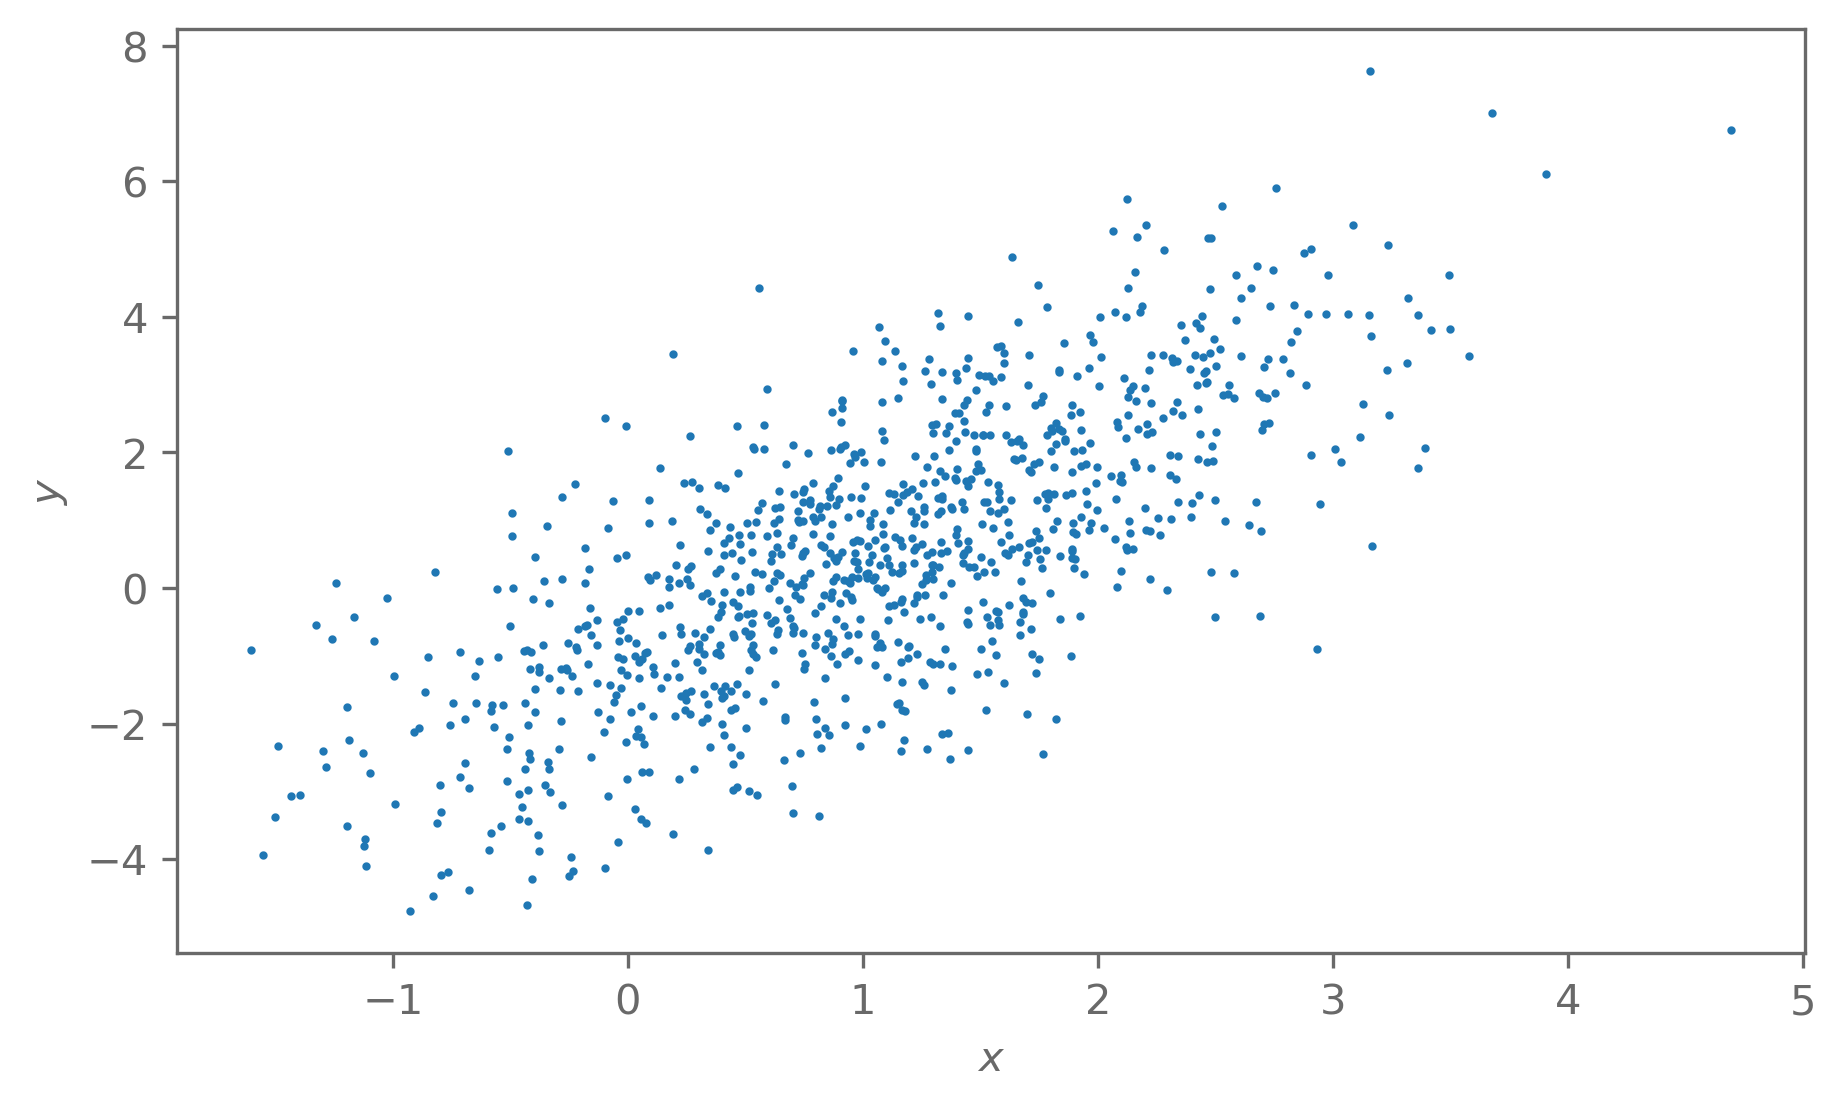

In [ ]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");

Acceptance rate: 55.17%


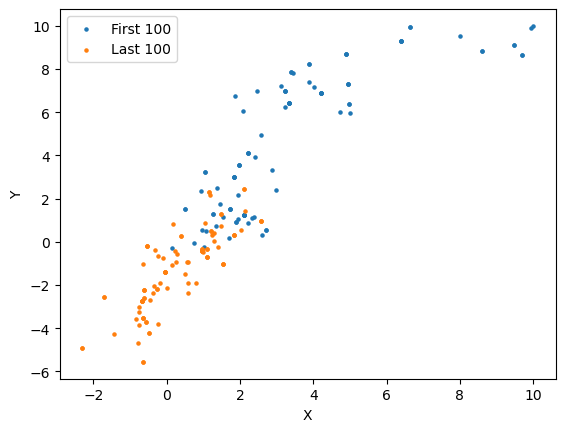

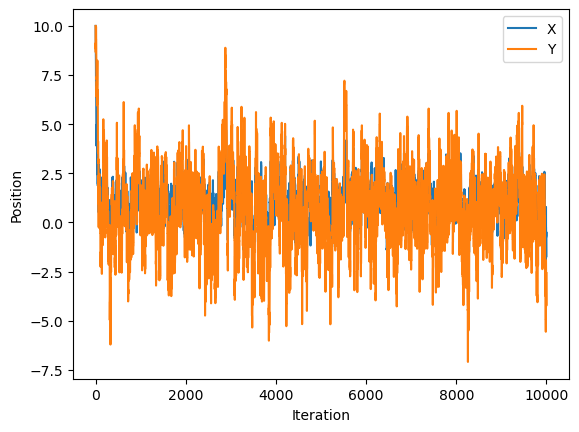

Theoretical mean: [1.  0.5]
Estimated mean: [1.02709369 0.59977725]
Theoretical covariance:
[[1.  1.4]
 [1.4 4. ]]
Estimated covariance:
[[1.07171966 1.55592493]
 [1.55592493 4.26054257]]


In [8]:

import numpy as np
import scipy.stats
import matplotlib.pyplot as plt

# Define target distribution
sigma_x = 1
sigma_y = 2
rho = 0.7

mean = np.array([1, 0.5])

cov = np.array([
    [sigma_x**2, sigma_x*sigma_y*rho],
    [sigma_x*sigma_y*rho, sigma_y**2]
])

target = scipy.stats.multivariate_normal(
    mean=mean, cov=cov
)

# Initialize Markov chain
N = 10000
x_current = np.array([10.0, 10.0])
chain = [x_current.copy()]
accepted_count = 0

# Metropolis-Hastings
for i in range(N):

    # Generate proposal
    epsilon = scipy.stats.norm(
        loc=0, scale=1
    ).rvs(size=2)

    x_proposed = x_current + epsilon

    # Calculate acceptance probability
    ratio = target.pdf(x_proposed) / target.pdf(x_current)
    alpha = min(1, ratio)

    # Accept or reject
    u = np.random.uniform(0, 1)

    if u <= alpha:
        x_current = x_proposed
        accepted_count += 1

    chain.append(x_current.copy())

chain = np.array(chain)

# Acceptance rate
accept_rate = accepted_count / N
print(f"Acceptance rate: {accept_rate:.2%}")

# Scatter plot: first and last 100 states
plt.scatter(chain[:100, 0], chain[:100, 1],
            s=5, label="First 100")
plt.scatter(chain[-100:, 0], chain[-100:, 1],
            s=5, label="Last 100")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.show()

# Trace plots
plt.plot(chain[:, 0], label="X")
plt.plot(chain[:, 1], label="Y")
plt.xlabel("Iteration")
plt.ylabel("Position")
plt.legend()
plt.show()

# Remove burn-in
burn_in = 100
samples = chain[burn_in:, :]

# Estimate mean and covariance
sample_mean = np.mean(samples, axis=0)
sample_cov = np.cov(samples, rowvar=False)

print("Theoretical mean:", mean)
print("Estimated mean:", sample_mean)
print("Theoretical covariance:")
print(cov)
print("Estimated covariance:")
print(sample_cov)
